# Notebook 03 - Treinamento e Avaliação do Modelo XGB

## Objetivos
- Treinar um modelo de classificação de risco de crédito (XGB) nos dados de referência.
- Comparar o desempenho do modelo **XGB** com os dados de **referência e produção**;
- Avaliar a performance período estável e driftado.

In [4]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


cwd = Path.cwd()
repo_root = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "src").is_dir()
        and (path / "config" / "config.yaml").is_file()
    ),
    None,
)
if repo_root is None:
    raise RuntimeError("Não encontrei a raiz do repositório.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.drift.data_drift_simulation import DRIFT_FILE, STABLE_FILE
from src.models.dataset import split_features_target
from src.utils.config_loader import PROJECT_ROOT, load_config
from src.utils.logging_config import configure_logging

configure_logging()
plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")

%matplotlib inline

## 1. Carregar o Modelo e os Dados

Carregamos o modelo treinado (obtido como artefato via train.py) e os dados de produção no período 1 (estável) e 2(drift)

In [5]:
config = load_config()
data_dir = PROJECT_ROOT / config.data.processed_path
model_path = (
    PROJECT_ROOT
    / config.artifacts.model_path
    / config.artifacts.model_file
)

prod1_estavel = pd.read_csv(data_dir / STABLE_FILE)
prod2_drift = pd.read_csv(data_dir / DRIFT_FILE)
model = joblib.load(model_path)

## 2. Previsões em Produção

In [6]:
threshold = config.model.prediction_threshold

# Separa TARGET para avaliação; ele não entra como feature do modelo
X_prod1, y_prod1 = split_features_target(prod1_estavel, config)
X_prod2, y_prod2 = split_features_target(prod2_drift, config)

# Probabilidade da classe 1 (default)
proba_prod1 = model.predict_proba(X_prod1)[:, 1]
proba_prod2 = model.predict_proba(X_prod2)[:, 1]

# Classes binárias usando o threshold configurado
pred_prod1 = (proba_prod1 >= threshold).astype(np.int8)
pred_prod2 = (proba_prod2 >= threshold).astype(np.int8)

# Resultados em memória, mantendo o alinhamento com os alvos
predictions_prod1 = pd.DataFrame(
    {
        "default_probability": proba_prod1,
        "prediction": pred_prod1,
    },
    index=prod1_estavel.index,
)

predictions_prod2 = pd.DataFrame(
    {
        "default_probability": proba_prod2,
        "prediction": pred_prod2,
    },
    index=prod2_drift.index,
)

## 3. Comparação de Métricas: Refêrencia vs Produção

In [8]:
def calculate_period_metrics(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "brier_score": brier_score_loss(y_true, y_proba),
        "average_precision": average_precision_score(y_true, y_proba),
    }

metrics_prod1 = calculate_period_metrics(
    y_prod1, pred_prod1, proba_prod1
)
metrics_prod2 = calculate_period_metrics(
    y_prod2, pred_prod2, proba_prod2
)

comparison = {
    metric: {
        "prod1_estavel": metrics_prod1[metric],
        "prod2_drift": metrics_prod2[metric],
        "delta": metrics_prod2[metric] - metrics_prod1[metric],
    }
    for metric in metrics_prod1
}

higher_is_better = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "average_precision",
}

print("Comparação do XGBoost: prod1 estável vs prod2 drift")
print("=" * 60)

for metric, values in comparison.items():
    delta = values["delta"]

    if np.isclose(delta, 0):
        trend = "sem variação"
    elif (delta > 0) == (metric in higher_is_better):
        trend = "melhorou nesta métrica"
    else:
        trend = "piorou nesta métrica"

    print(
        f"{metric:18s}: "
        f"prod1={values['prod1_estavel']:.4f} → "
        f"prod2={values['prod2_drift']:.4f} "
        f"(Δ={delta:+.4f}; {trend})"
    )

Comparação do XGBoost: prod1 estável vs prod2 drift
accuracy          : prod1=0.7165 → prod2=0.6165 (Δ=-0.1000; piorou nesta métrica)
precision         : prod1=0.1740 → prod2=0.2213 (Δ=+0.0473; melhorou nesta métrica)
recall            : prod1=0.6698 → prod2=0.8715 (Δ=+0.2018; melhorou nesta métrica)
f1                : prod1=0.2762 → prod2=0.3529 (Δ=+0.0767; melhorou nesta métrica)
roc_auc           : prod1=0.7628 → prod2=0.8169 (Δ=+0.0540; melhorou nesta métrica)
brier_score       : prod1=0.1875 → prod2=0.2325 (Δ=+0.0450; piorou nesta métrica)
average_precision : prod1=0.2464 → prod2=0.3938 (Δ=+0.1475; melhorou nesta métrica)


In [9]:
def plot_metrics_comparison(
    metrics_prod1,
    metrics_prod2,
    title="Métricas do XGBoost: prod1 estável vs prod2 drift",
    save_path=None,
):
    metric_names = [
        "accuracy", "precision", "recall", "f1",
        "roc_auc", "brier_score", "average_precision",
    ]
    metrics = [
        name for name in metric_names
        if name in metrics_prod1 and name in metrics_prod2
    ]
    labels = [name.replace("_", "\n") for name in metrics]
    x = np.arange(len(metrics))
    width = 0.36

    fig, ax = plt.subplots(figsize=(12, 6))
    bars1 = ax.bar(
        x - width / 2, [metrics_prod1[m] for m in metrics],
        width, label="prod1 estável", color="steelblue",
    )
    bars2 = ax.bar(
        x + width / 2, [metrics_prod2[m] for m in metrics],
        width, label="prod2 drift", color="coral",
    )

    ax.set(title=title, ylabel="Valor da métrica")
    ax.set_xticks(x, labels, rotation=20, ha="right")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    ax.bar_label(bars1, fmt="%.3f", padding=2, fontsize=8)
    ax.bar_label(bars2, fmt="%.3f", padding=2, fontsize=8)
    fig.text(
        0.5, 0.01,
        "Brier score: menor é melhor. Nas demais métricas, maior é melhor.",
        ha="center",
    )
    fig.tight_layout(rect=[0, 0.04, 1, 1])

    if save_path is not None:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=150, bbox_inches="tight")

    return fig, ax

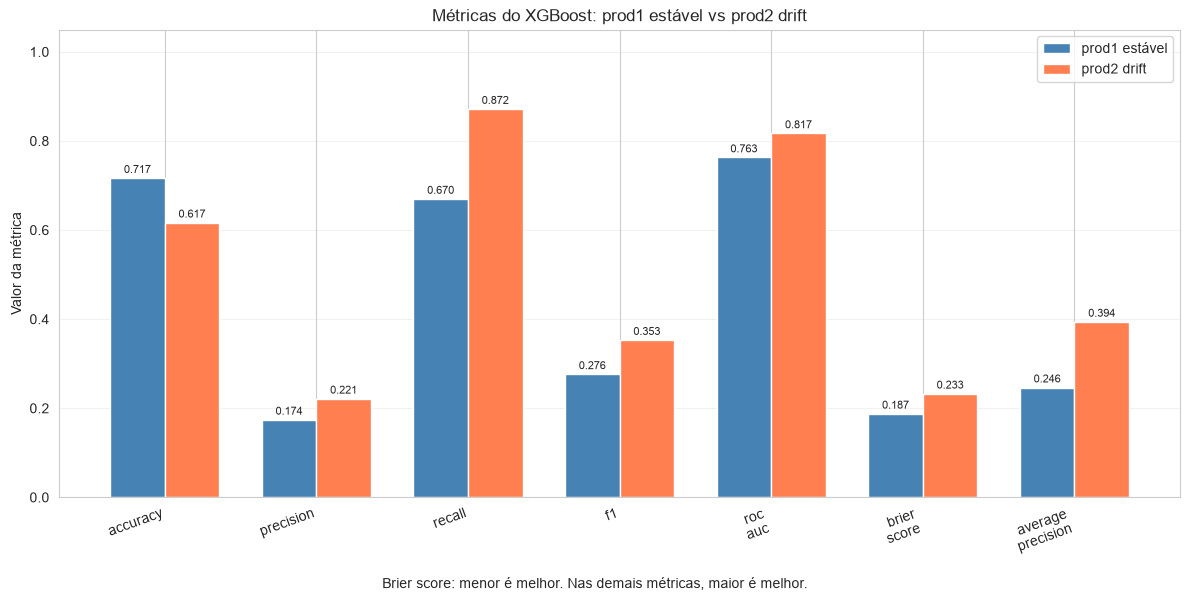

In [12]:
fig, ax = plot_metrics_comparison(
    metrics_prod1,
    metrics_prod2,
    save_path=PROJECT_ROOT / "reports" / "xgboost_prod1_vs_prod2.png",
)
plt.show()

## 4. Brier Score - Calibração sob Drift

In [11]:
# Brier Score: prod1 estável vs prod2 drift
brier_prod1 = brier_score_loss(y_prod1, proba_prod1)
brier_prod2 = brier_score_loss(y_prod2, proba_prod2)
delta_brier = brier_prod2 - brier_prod1

print(f"Brier Score (prod1 estável): {brier_prod1:.4f}")
print(f"Brier Score (prod2 drift):   {brier_prod2:.4f}")
print(f"Variação (prod2 - prod1):    {delta_brier:+.4f}")

if delta_brier > 0:
    print("O Brier aumentou em prod2: score probabilístico pior contra o alvo desse período.")
elif delta_brier < 0:
    print("O Brier diminuiu em prod2: score probabilístico melhor contra o alvo desse período.")
else:
    print("O Brier não variou entre os períodos.")

Brier Score (prod1 estável): 0.1875
Brier Score (prod2 drift):   0.2325
Variação (prod2 - prod1):    +0.0450
O Brier aumentou em prod2: score probabilístico pior contra o alvo desse período.


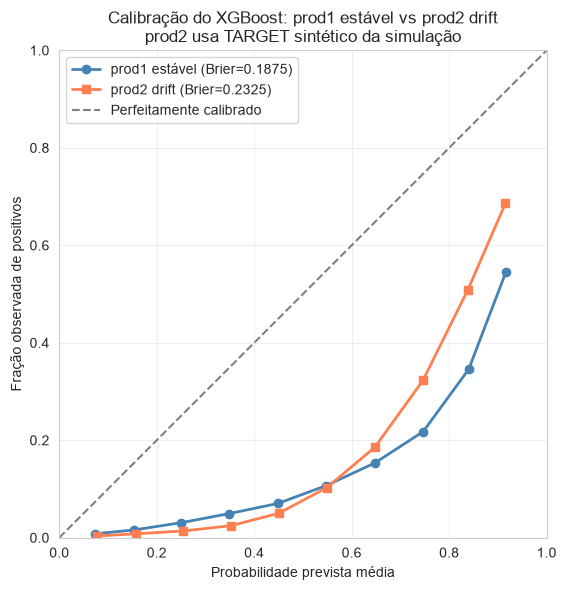

In [13]:
# Curvas de calibração do XGBoost: prod1 estável vs prod2 drift
frac_prod1, mean_prod1 = calibration_curve(
    y_prod1,
    proba_prod1,
    n_bins=10,
    strategy="uniform",
)

frac_prod2, mean_prod2 = calibration_curve(
    y_prod2,
    proba_prod2,
    n_bins=10,
    strategy="uniform",
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    mean_prod1,
    frac_prod1,
    marker="o",
    linewidth=2,
    color="steelblue",
    label=f"prod1 estável (Brier={metrics_prod1['brier_score']:.4f})",
)

ax.plot(
    mean_prod2,
    frac_prod2,
    marker="s",
    linewidth=2,
    color="coral",
    label=f"prod2 drift (Brier={metrics_prod2['brier_score']:.4f})",
)

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Perfeitamente calibrado",
)

ax.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Probabilidade prevista média",
    ylabel="Fração observada de positivos",
    title=(
        "Calibração do XGBoost: prod1 estável vs prod2 drift\n"
        "prod2 usa TARGET sintético da simulação"
    ),
)
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

figure_path = PROJECT_ROOT / "reports" / "xgboost_calibration_prod1_vs_prod2.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")

plt.show()

## 5. Matriz de Confusão - Produção

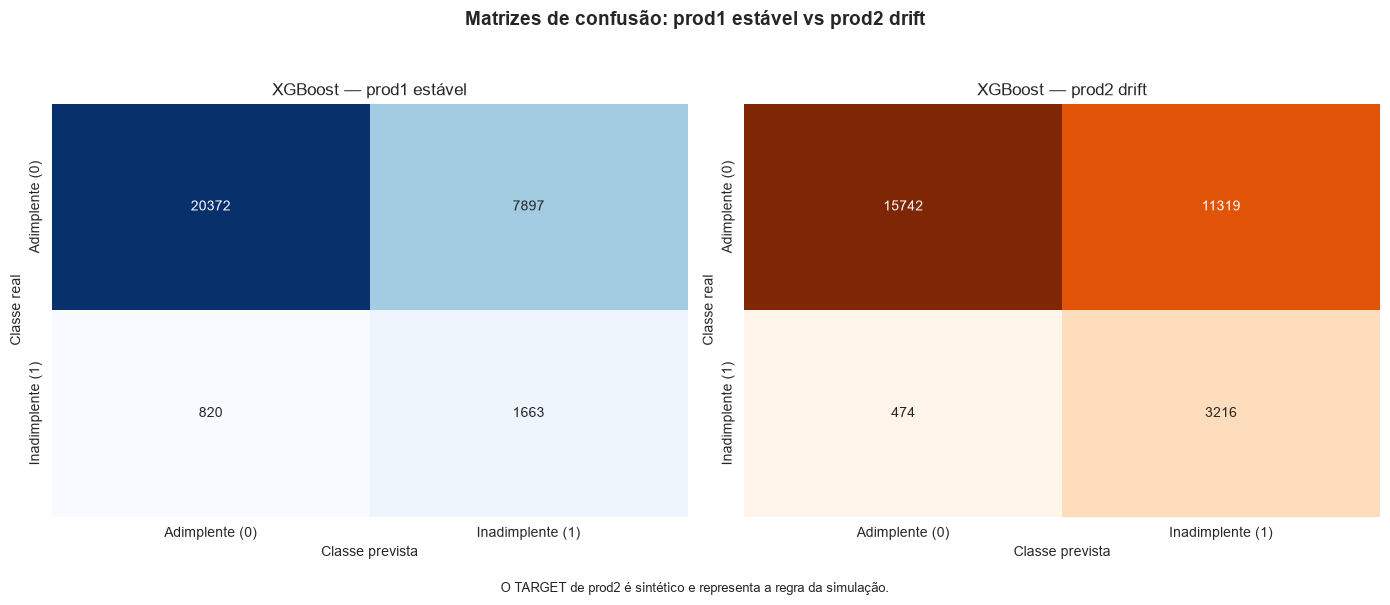

In [14]:
# Matrizes de confusão: prod1 estável vs prod2 drift
class_labels = ["Adimplente (0)", "Inadimplente (1)"]

cm_prod1 = confusion_matrix(y_prod1, pred_prod1, labels=[0, 1])
cm_prod2 = confusion_matrix(y_prod2, pred_prod2, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(
    cm_prod1,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[0],
)
axes[0].set_title("XGBoost — prod1 estável")
axes[0].set_xlabel("Classe prevista")
axes[0].set_ylabel("Classe real")

sns.heatmap(
    cm_prod2,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[1],
)
axes[1].set_title("XGBoost — prod2 drift")
axes[1].set_xlabel("Classe prevista")
axes[1].set_ylabel("Classe real")

fig.suptitle(
    "Matrizes de confusão: prod1 estável vs prod2 drift",
    fontsize=14,
    fontweight="bold",
)
fig.text(
    0.5,
    0.01,
    "O TARGET de prod2 é sintético e representa a regra da simulação.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])

figure_path = PROJECT_ROOT / "reports" / "xgboost_confusion_matrices_prod1_vs_prod2.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")

plt.show()

## 6. Conclusão

## Conclusão

A comparação do XGBoost entre `prod1` estável e `prod2` com drift apresentou resultados mistos. A acurácia caiu de 0,7165 para 0,6165, enquanto precisão, recall, F1, ROC-AUC e average precision aumentaram. Portanto, o drift não reduziu todas as métricas da mesma forma, e a melhora em algumas delas não significa, isoladamente, que o modelo passou a ter um desempenho geral melhor.

A matriz de confusão ajuda a entender esse comportamento no limiar de decisão utilizado: em `prod2`, o modelo identificou mais inadimplentes, mas reconheceu menos adimplentes. Isso significa mais bons pagadores classificados como inadimplentes, o que pode levar à recusa de crédito para clientes que pagariam em dia. Há, assim, um trade-off entre reduzir inadimplentes classificados como bons pagadores e evitar classificar bons pagadores como inadimplentes. A precisão também aumentou; isso indica uma proporção maior de acertos entre as previsões de inadimplência, mas não impede que a quantidade de falsos positivos tenha aumentado.

O Brier Score passou de 0,1875 em `prod1` para 0,2325 em `prod2`. Como valores menores são melhores, esse aumento indica que as probabilidades previstas tiveram maior erro quadrático em relação aos rótulos avaliados em `prod2`. O Brier Score resume a qualidade das previsões probabilísticas e não mede apenas calibração; por isso, deve ser interpretado junto com as curvas de calibração.

Na curva de calibração, pontos abaixo da diagonal indicam que o modelo prevê um risco de inadimplência maior do que a frequência observada naquele intervalo; pontos acima indicam o contrário. Se houver afastamento relevante da diagonal, uma recalibração pode ser investigada usando dados rotulados representativos e separados dos dados usados para avaliar o resultado. A recalibração pode melhorar a confiabilidade das probabilidades, mas não corrige, por si só, problemas de discriminação ou o trade-off definido pelo limiar de decisão.

Os resultados de `prod2` precisam ser interpretados como parte de uma simulação: seu `TARGET` é sintético e depende de uma regra baseada em características dos dados. Essa regra pode favorecer métricas de ranking, como ROC-AUC e average precision, quando está alinhada às variáveis usadas pelo modelo. Assim, as métricas de `prod2` ajudam a analisar o comportamento do XGBoost diante do cenário simulado, mas não comprovam melhora ou piora do desempenho em uma produção real com rótulos observados.

Em conjunto, os resultados mostram que avaliar drift exige observar várias métricas, a matriz de confusão, a calibração e o limiar de decisão. Nenhuma métrica isolada resume todos os impactos: o modelo pode detectar mais inadimplentes e, ao mesmo tempo, aumentar o risco de penalizar bons pagadores.